In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
torch.manual_seed(1)


x_train = torch.FloatTensor([[1, 2, 1],
                             [1, 3, 2],
                             [1, 3, 4],
                             [1, 5, 5],
                             [1, 7, 5],
                             [1, 2, 5],
                             [1, 6, 6],
                             [1, 7, 7]
                            ])
y_train = torch.LongTensor([2, 2, 2, 1, 1, 1, 0, 0])

x_test = torch.FloatTensor([[2, 1, 1], [3, 1, 2], [3, 3, 4]])
y_test = torch.LongTensor([2, 2, 2])

class SoftmaxClassifierModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(3, 3)  

    def forward(self, x):
        return self.linear(x)
    
model = SoftmaxClassifierModel()
optimizer = optim.SGD(model.parameters(), lr=0.1)
def train(model,optimizer,x_train,y_train):
    nb_epochs = 20
    for epoch in range(nb_epochs + 1):
        prediction = model(x_train)
        cost = F.cross_entropy(prediction, y_train)
        optimizer.zero_grad()
        cost.backward()
        optimizer.step()
        print('Epoch {:4d}/{} Cost: {:.6f}'.format(
            epoch, nb_epochs, cost.item()
        ))
def test(model,optimizer,x_test,y_test):
    prediction = model(x_test)
    cost = F.cross_entropy(prediction, y_test)
    predicted_classes = prediction.max(1)[1]
    correct_count = (predicted_classes == y_test).sum().item()
    accuracy = correct_count / len(y_test)
    print('Test Cost: {:.6f} Accuracy: {:.2f}%'.format(
        cost.item(), accuracy * 100
    ))  
train(model,optimizer,x_train,y_train)
test(model,optimizer,x_test,y_test)

Epoch    0/20 Cost: 2.203667
Epoch    1/20 Cost: 1.199645
Epoch    2/20 Cost: 1.142985
Epoch    3/20 Cost: 1.117769
Epoch    4/20 Cost: 1.100901
Epoch    5/20 Cost: 1.089523
Epoch    6/20 Cost: 1.079872
Epoch    7/20 Cost: 1.071320
Epoch    8/20 Cost: 1.063325
Epoch    9/20 Cost: 1.055720
Epoch   10/20 Cost: 1.048378
Epoch   11/20 Cost: 1.041245
Epoch   12/20 Cost: 1.034285
Epoch   13/20 Cost: 1.027478
Epoch   14/20 Cost: 1.020813
Epoch   15/20 Cost: 1.014279
Epoch   16/20 Cost: 1.007872
Epoch   17/20 Cost: 1.001586
Epoch   18/20 Cost: 0.995419
Epoch   19/20 Cost: 0.989365
Epoch   20/20 Cost: 0.983424
Test Cost: 1.386150 Accuracy: 0.00%


In [4]:

x_train = torch.FloatTensor([[73, 80, 75],
                             [93, 88, 93],
                             [89, 91, 90],
                             [96, 98, 100],
                             [73, 66, 70]])
y_train = torch.FloatTensor([[152], [185], [180], [196], [142]])
mu = x_train.mean(dim=0)
sigma = x_train.std(dim=0)
x_train = (x_train - mu) / sigma
class MultivariateLinearRegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(3, 1)

    def forward(self, x):
        return self.linear(x)
    
model = MultivariateLinearRegressionModel()
optimizer = optim.SGD(model.parameters(), lr=1e-1)
def train(model,optimizer,x_train,y_train):
    nb_epochs = 20
    for epoch in range(nb_epochs + 1):
        predictionq = model(x_train)
        cost = F.mse_loss(predictionq, y_train)
        optimizer.zero_grad()
        cost.backward()
        optimizer.step()
        print('Epoch {:4d}/{} Cost: {:.6f}'.format(
            epoch, nb_epochs, cost.item()
        ))
train(model,optimizer,x_train,y_train)

Epoch    0/20 Cost: 29579.208984
Epoch    1/20 Cost: 18791.833984
Epoch    2/20 Cost: 11986.543945
Epoch    3/20 Cost: 7659.861816
Epoch    4/20 Cost: 4899.133301
Epoch    5/20 Cost: 3134.692383
Epoch    6/20 Cost: 2006.150391
Epoch    7/20 Cost: 1284.081787
Epoch    8/20 Cost: 822.010925
Epoch    9/20 Cost: 526.295776
Epoch   10/20 Cost: 337.036438
Epoch   11/20 Cost: 215.905518
Epoch   12/20 Cost: 138.375519
Epoch   13/20 Cost: 88.750931
Epoch   14/20 Cost: 56.985199
Epoch   15/20 Cost: 36.649635
Epoch   16/20 Cost: 23.629509
Epoch   17/20 Cost: 15.291476
Epoch   18/20 Cost: 9.950250
Epoch   19/20 Cost: 6.527026
Epoch   20/20 Cost: 4.331639


[Epoch:    1] cost = 0.535150647
[Epoch:    2] cost = 0.359577775
[Epoch:    3] cost = 0.331264257
[Epoch:    4] cost = 0.3164047
[Epoch:    5] cost = 0.307107002
[Epoch:    6] cost = 0.300456554
[Epoch:    7] cost = 0.294933408
[Epoch:    8] cost = 0.290956199
[Epoch:    9] cost = 0.287074119
[Epoch:   10] cost = 0.284515619
[Epoch:   11] cost = 0.281914085
[Epoch:   12] cost = 0.279526889
[Epoch:   13] cost = 0.277636588
[Epoch:   14] cost = 0.275874794
[Epoch:   15] cost = 0.274422765
Accuracy: 0.888300
Label:  8
Prediction:  3


d:\deeplearning\.venv\Lib\site-packages\torchvision\datasets\mnist.py:81: UserWarning: test_data has been renamed data
  warnings.warn("test_data has been renamed data")
d:\deeplearning\.venv\Lib\site-packages\torchvision\datasets\mnist.py:71: UserWarning: test_labels has been renamed targets
  warnings.warn("test_labels has been renamed targets")


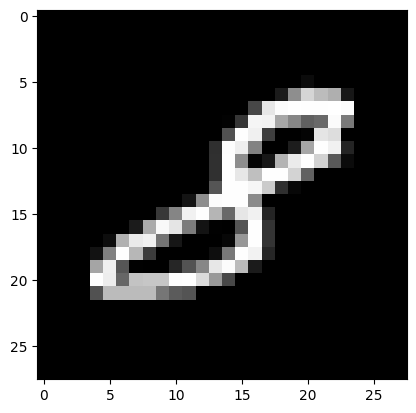

In [3]:
import torch
import torchvision.datasets as dsets
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import random
device = 'cuda' if torch.cuda.is_available() else 'cpu'
random.seed(777)
torch.manual_seed(777)
if device == 'cuda':
    torch.cuda.manual_seed_all(777)
    
training_epochs = 15
batch_size = 100

mnist_train = dsets.MNIST(root='MNIST_data/',
                          train=True,
                          transform=transforms.ToTensor(),
                          download=True)
mnist_test = dsets.MNIST(root='MNIST_data/',
                         train=False,
                         transform=transforms.ToTensor(),
                         download=True)

data_loader = torch.utils.data.DataLoader(dataset=mnist_train,
                                          batch_size=batch_size,
                                          shuffle=True,
                                          drop_last=True)

linear = torch.nn.Linear(784,10,bias=True).to(device)#即b
criterion = torch.nn.CrossEntropyLoss().to(device)
optimizer = torch.optim.SGD(linear.parameters(),lr=0.1)
for epoch in range(training_epochs):
    avg_cost = 0
    total_batch = len(data_loader)
    
    for X,Y in data_loader:
        X = X.view(-1,28*28).to(device)
        Y = Y.to(device)
        
        optimizer.zero_grad()
        hypothesis = linear(X)
        cost = criterion(hypothesis,Y)
        cost.backward()
        optimizer.step()
        avg_cost += cost / total_batch 
    print('[Epoch: {:>4}] cost = {:>.9}'.format(epoch + 1, avg_cost))

with torch.no_grad():
    X_test = mnist_test.test_data.view(-1,28*28).float().to(device)
    Y_test = mnist_test.test_labels.to(device)
    prediction = linear(X_test)                 
    correct_prediction = torch.argmax(prediction,1) == Y_test
    accuracy = correct_prediction.float().mean()
    print('Accuracy: {:>.6f}'.format(accuracy.item()))
    
    r = random.randint(0, len(mnist_test) - 1)
    X_single_data = mnist_test.test_data[r:r + 1].view(-1, 28 * 28).float().to(device)
    Y_single_data = mnist_test.test_labels[r:r + 1].to(device)
    print('Label: ', Y_single_data.item())
    single_prediction = linear(X_single_data)
    print('Prediction: ', torch.argmax(single_prediction, 1).item())
    plt.imshow(mnist_test.test_data[r:r + 1].view(28, 28), cmap='gray')
    plt.show()